**DATA LOADING**

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"

df = pd.read_csv(url)

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
from pathlib import Path

data_dir = Path.cwd().parent / "data"
data_dir.mkdir(exist_ok=True)

df.to_csv(data_dir / "insurance.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


**EDA**

In [3]:
print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

Dataset shape: (1338, 7)

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB

Statistical summary:


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [4]:
df.shape

(1338, 7)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [17]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

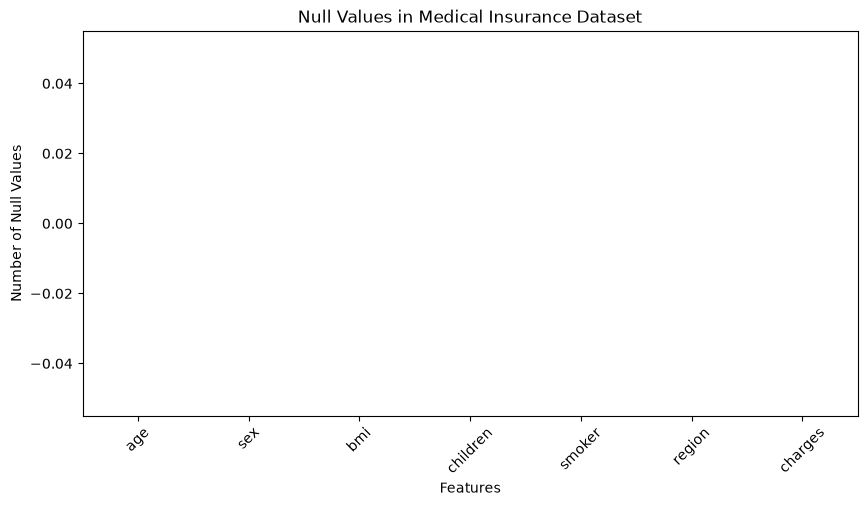

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

df.isnull().sum().plot(kind='bar', color='skyblue')

plt.xlabel("Features")
plt.ylabel("Number of Null Values")
plt.title("Null Values in Medical Insurance Dataset")
plt.xticks(rotation=45)
plt.show()

In [7]:
df.duplicated().sum()

np.int64(1)

In [8]:
df = df.drop_duplicates().reset_index(drop=True)

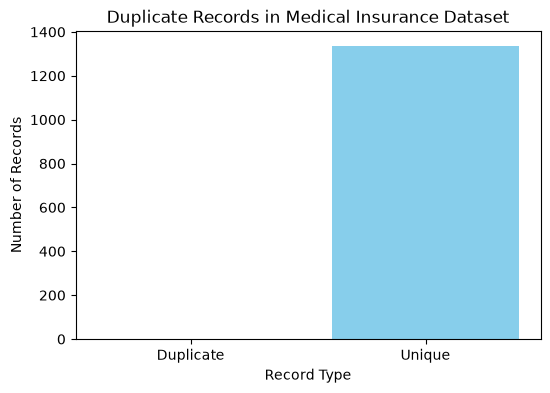

In [21]:
import matplotlib.pyplot as plt

duplicate = df.duplicated().sum()
unique = len(df) - duplicate

plt.figure(figsize=(6, 4))

plt.bar(['Duplicate', 'Unique'], [duplicate, unique],
        color=['red', 'skyblue'])

plt.xlabel('Record Type')
plt.ylabel('Number of Records')
plt.title('Duplicate Records in Medical Insurance Dataset')

plt.show()

In [9]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


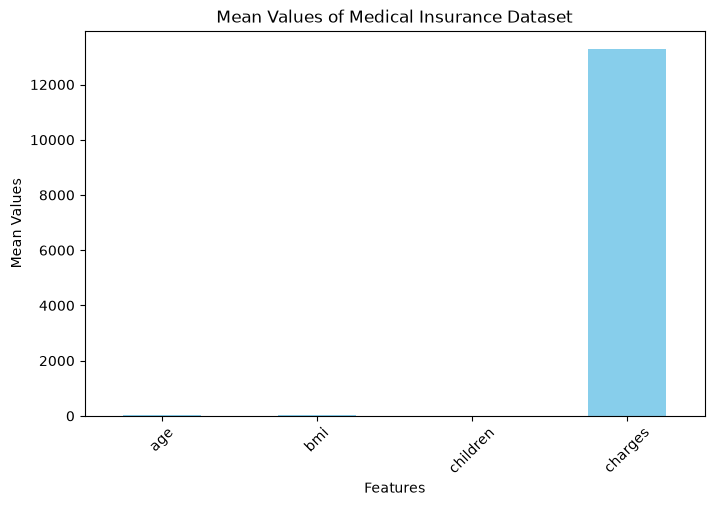

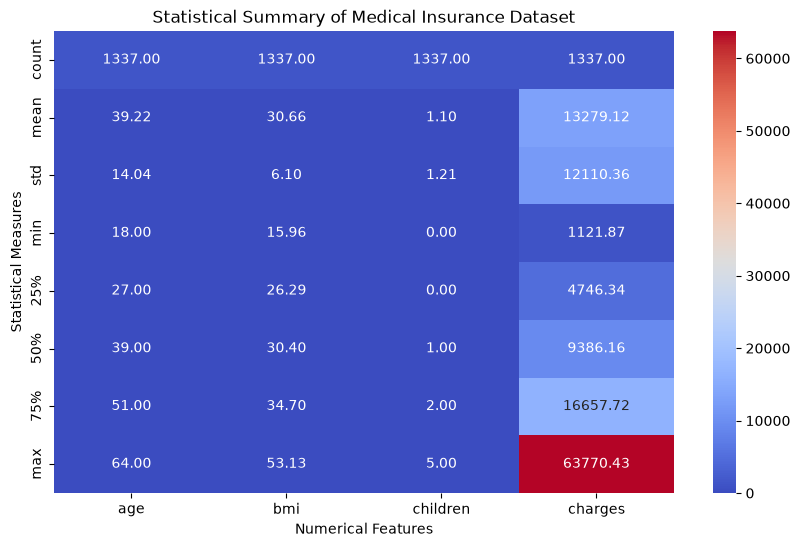

C:\Users\VANDAN KUMAR\AppData\Local\Temp\ipykernel_38188\679731131.py:28: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,sex,smoker,region
count,1337,1337,1337
unique,2,2,4
top,male,no,southeast
freq,675,1063,364


In [22]:
import matplotlib.pyplot as plt

df.describe().loc['mean'].plot(
    kind='bar',
    color='skyblue',
    figsize=(8, 5)
)

plt.xlabel('Features')
plt.ylabel('Mean Values')
plt.title('Mean Values of Medical Insurance Dataset')
plt.xticks(rotation=45)
plt.show()


import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.heatmap(df.describe(), annot=True, cmap='coolwarm', fmt='.2f')

plt.xlabel('Numerical Features')
plt.ylabel('Statistical Measures')
plt.title('Statistical Summary of Medical Insurance Dataset')
plt.show()

df.describe(include='object')

**Visualize medical charges**

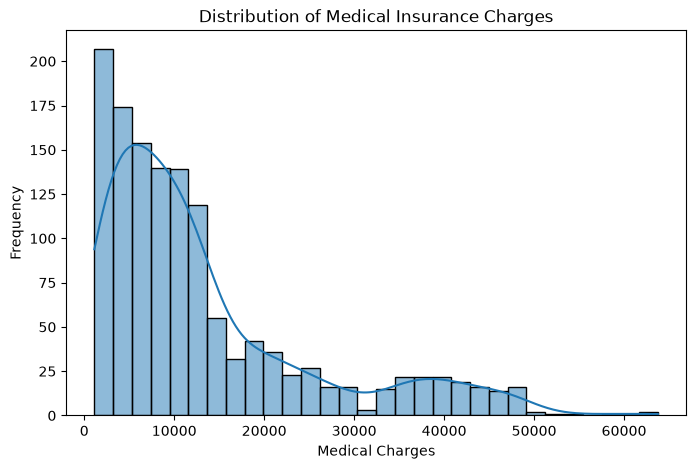

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["charges"], bins=30, kde=True)
plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Medical Charges")
plt.ylabel("Frequency")
plt.show()

**Analyze smoking status vs charges**

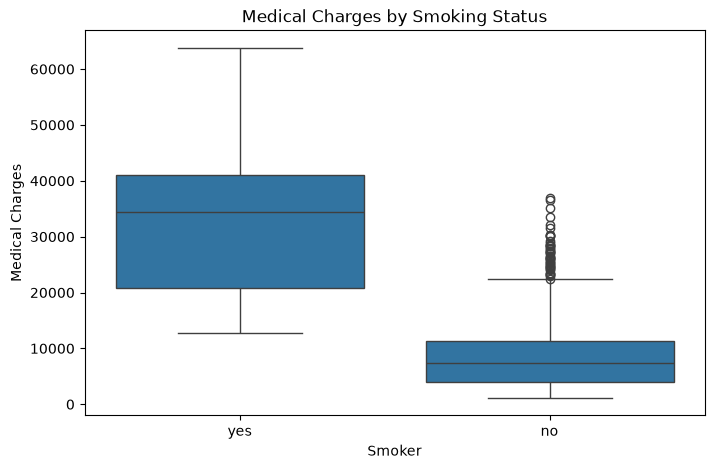

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Medical Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Medical Charges")
plt.show()

**Correlation heatmap**

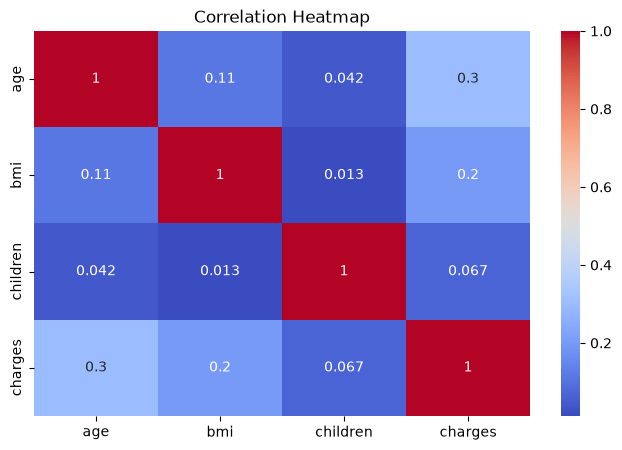

In [12]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Heatmap")
plt.show()